In [7]:
!pip install google-api-python-client pandas -q
import pandas as pd
from googleapiclient.discovery import build
from googleapiclient.errors import HttpError
from google.colab import userdata

youtube = build("youtube", "v3", developerKey=userdata.get("youtube_api_key"))

MIN_VIDEOS = 200
MAX_VIDEOS = 10000
MAX_COMMENTS_PER_VIDEO = 50

# Candidate property channels (add or remove names as you like)
CANDIDATES = ["Zameen.com", "Graana.com", "Lahore Smart City", "Capital Smart City",
              "Bahria Town Pakistan", "Blue World City", "DHA Lahore", "Park View City"]

# 1. Find the first channel with at least 200 videos
channel_id, channel_title = None, None
best = (None, None, 0)
for name in CANDIDATES:
    try:
        s = youtube.search().list(part="snippet", q=name, type="channel", maxResults=1).execute()
        if not s["items"]:
            continue
        cid = s["items"][0]["snippet"]["channelId"]
        title = s["items"][0]["snippet"]["channelTitle"]
        info = youtube.channels().list(part="statistics,contentDetails", id=cid).execute()["items"][0]
        count = int(info["statistics"].get("videoCount", 0))
        print(f"{name} -> '{title}' has {count} videos")
        if count > best[2]:
            best = (cid, title, count)
        if count >= MIN_VIDEOS:
            channel_id, channel_title = cid, title
            uploads = info["contentDetails"]["relatedPlaylists"]["uploads"]
            break
    except HttpError as e:
        raise SystemExit(f"API error: {e}")

if channel_id is None:
    raise SystemExit(f"No candidate has {MIN_VIDEOS}+ videos. Largest was '{best[1]}' with {best[2]}. Add more names to CANDIDATES.")

print(f"\n✅ Using channel: {channel_title}")

# 2. Video IDs
video_ids, token = [], None
while len(video_ids) < MAX_VIDEOS:
    r = youtube.playlistItems().list(part="contentDetails", playlistId=uploads,
                                     maxResults=50, pageToken=token).execute()
    video_ids += [i["contentDetails"]["videoId"] for i in r["items"]]
    token = r.get("nextPageToken")
    if not token:
        break
video_ids = video_ids[:MAX_VIDEOS]
print("Videos found:", len(video_ids))

# 3. Video details
videos = []
for i in range(0, len(video_ids), 50):
    r = youtube.videos().list(part="snippet,statistics", id=",".join(video_ids[i:i+50])).execute()
    for v in r["items"]:
        st = v["statistics"]
        videos.append({"video_id": v["id"], "title": v["snippet"]["title"],
                       "published": v["snippet"]["publishedAt"],
                       "views": int(st.get("viewCount", 0)),
                       "likes": int(st.get("likeCount", 0)),
                       "comment_count": int(st.get("commentCount", 0))})
videos_df = pd.DataFrame(videos)

# 4. Comments
comments = []
for n, vid in enumerate(videos_df.video_id, 1):
    try:
        token, got = None, 0
        while got < MAX_COMMENTS_PER_VIDEO:
            r = youtube.commentThreads().list(part="snippet", videoId=vid, maxResults=min(100, MAX_COMMENTS_PER_VIDEO),
                                              pageToken=token, textFormat="plainText").execute()
            for c in r["items"]:
                sn = c["snippet"]["topLevelComment"]["snippet"]
                comments.append({"video_id": vid, "comment": sn["textDisplay"],
                                 "likes": sn["likeCount"], "date": sn["publishedAt"]})
            got += len(r["items"])
            token = r.get("nextPageToken")
            if not token:
                break
    except HttpError:
        pass  # comments disabled on this video
    if n % 25 == 0:
        print(f"  processed {n}/{len(videos_df)} videos, {len(comments)} comments so far")

comments_df = pd.DataFrame(comments)
videos_df.to_csv("property_videos.csv", index=False)
comments_df.to_csv("property_comments.csv", index=False)
print(f"\nDone: {len(videos_df)} videos, {len(comments_df)} comments")

Zameen.com -> 'Zameen.com' has 125585 videos

✅ Using channel: Zameen.com
Videos found: 10000
  processed 25/10000 videos, 4 comments so far
  processed 50/10000 videos, 16 comments so far
  processed 75/10000 videos, 18 comments so far
  processed 100/10000 videos, 25 comments so far
  processed 125/10000 videos, 29 comments so far
  processed 150/10000 videos, 32 comments so far
  processed 175/10000 videos, 35 comments so far
  processed 200/10000 videos, 38 comments so far
  processed 225/10000 videos, 44 comments so far
  processed 250/10000 videos, 55 comments so far
  processed 275/10000 videos, 58 comments so far
  processed 300/10000 videos, 61 comments so far
  processed 325/10000 videos, 66 comments so far
  processed 350/10000 videos, 70 comments so far
  processed 375/10000 videos, 73 comments so far
  processed 400/10000 videos, 85 comments so far
  processed 425/10000 videos, 92 comments so far
  processed 450/10000 videos, 94 comments so far
  processed 475/10000 videos

  processed 2350/10000 videos, 357 comments so far
  processed 2375/10000 videos, 363 comments so far
  processed 2400/10000 videos, 365 comments so far
  processed 2425/10000 videos, 366 comments so far
  processed 2450/10000 videos, 374 comments so far
  processed 2475/10000 videos, 378 comments so far
  processed 2500/10000 videos, 380 comments so far
  processed 2525/10000 videos, 381 comments so far
  processed 2550/10000 videos, 384 comments so far
  processed 2575/10000 videos, 393 comments so far
  processed 2600/10000 videos, 396 comments so far
  processed 2625/10000 videos, 399 comments so far
  processed 2650/10000 videos, 402 comments so far
  processed 2675/10000 videos, 409 comments so far
  processed 2700/10000 videos, 417 comments so far
  processed 2725/10000 videos, 417 comments so far
  processed 2750/10000 videos, 423 comments so far
  processed 2775/10000 videos, 427 comments so far
  processed 2800/10000 videos, 430 comments so far
  processed 2825/10000 videos, 

  processed 9300/10000 videos, 1371 comments so far


  processed 9325/10000 videos, 1376 comments so far


  processed 9350/10000 videos, 1376 comments so far


  processed 9375/10000 videos, 1376 comments so far


... (21 outputs left out)

  processed 9925/10000 videos, 1376 comments so far


  processed 9950/10000 videos, 1376 comments so far


  processed 9975/10000 videos, 1376 comments so far


  processed 10000/10000 videos, 1376 comments so far

Done: 10000 videos, 1376 comments


In [8]:
import pandas as pd
import re

comments_df = pd.read_csv("property_comments.csv")
videos_df = pd.read_csv("property_videos.csv")
print("Before cleaning:", len(comments_df))

# 1. Remove empty comments
comments_df = comments_df.dropna(subset=["comment"])
comments_df["comment"] = comments_df["comment"].astype(str).str.strip()
comments_df = comments_df[comments_df["comment"] != ""]

# 2. Remove duplicates (same text on the same video)
comments_df = comments_df.drop_duplicates(subset=["video_id", "comment"])

# 3. Remove emoji-only comments (no letters in any language)
def has_text(t):
    return bool(re.search(r"[A-Za-z\u0600-\u06FF\u0750-\u077F]", t))

comments_df = comments_df[comments_df["comment"].apply(has_text)]

# 4. Remove very short comments (1-2 characters carry no sentiment)
comments_df = comments_df[comments_df["comment"].str.len() > 2]

# 5. Add a cleaned text column (keeps original untouched)
def clean_text(t):
    t = re.sub(r"http\S+", "", t)       # remove links
    t = re.sub(r"\s+", " ", t).strip()  # fix extra spaces
    return t

comments_df["clean_comment"] = comments_df["comment"].apply(clean_text)
comments_df = comments_df[comments_df["clean_comment"] != ""].reset_index(drop=True)

print("After cleaning:", len(comments_df))
comments_df.to_csv("property_comments_clean.csv", index=False)
comments_df.head()

Before cleaning: 1376
After cleaning: 1293


,video_id,comment,likes,date,clean_comment
0,IPc-7OYBUAA,Sir bechna chahta hon nahi bick raha,0,2026-11-04T12:57:29Z,Sir bechna chahta hon nahi bick raha
1,Z-tTRvLUlf0,Great👍👍,0,2026-11-05T21:09:29Z,Great👍👍
2,Z-tTRvLUlf0,Masha Allah mola or izat tarqi deh ameen,0,2026-11-05T15:23:27Z,Masha Allah mola or izat tarqi deh ameen
3,Z-tTRvLUlf0,💯 recommended,0,2026-11-05T12:40:45Z,💯 recommended
4,yuWlAsCBfIQ,Very good,0,2026-10-27T06:25:41Z,Very good


In [10]:
!pip install transformers torch -q
import pandas as pd
from transformers import pipeline

df = pd.read_csv("property_comments_clean.csv")

# Free multilingual model (supports English, Urdu and 6 other languages)
classifier = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    truncation=True,
    max_length=128,
    device=0,          # use GPU; change to -1 if you have no GPU
)

texts = df["clean_comment"].tolist()
results = classifier(texts, batch_size=32)

df["sentiment"] = [r["label"].lower() for r in results]   # positive / neutral / negative
df["confidence"] = [round(r["score"], 3) for r in results]

df.to_csv("property_comments_sentiment.csv", index=False)
print(df["sentiment"].value_counts())
print((df["sentiment"].value_counts(normalize=True) * 100).round(1))
df[["clean_comment", "sentiment", "confidence"]].sample(15, random_state=1)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentiment
neutral     983
positive    229
negative     81
Name: count, dtype: int64
sentiment
neutral     76.0
positive    17.7
negative     6.3
Name: proportion, dtype: float64


,clean_comment,sentiment,confidence
966,Covered area ? Demand ? Block ?,neutral,0.545
647,Price please?,neutral,0.733
60,AoA Mattital road pr Konsa project hai ??,neutral,0.609
936,Demand Kia he.,neutral,0.372
948,Scheme 33 portion too bad didi,negative,0.955
876,Very good ❤❤❤❤,positive,0.912
133,When this project will be completed,neutral,0.795
142,How to contact ? ….. kiya rate ha ?,neutral,0.614
453,Price??,neutral,0.556
409,Assalam walekum bhaiya society kis site per,neutral,0.396


type
Other                 8683
Development Update    1188
Investment Advice       70
Walkthrough/Tour        40
Project Launch          19
Name: count, dtype: int64 

                    videos  avg_views  avg_likes  avg_comments  total  \
type                                                                    
Development Update    1188     9937.8        4.0           0.2    132   
Investment Advice       70      843.4        2.0           0.2      9   
Other                 8683     1773.6        1.4           0.3   1143   
Project Launch          19      896.4        2.7           0.2      2   
Walkthrough/Tour        40      370.2        3.2           0.4      7   

                    pct_positive  pct_negative  
type                                            
Development Update          43.2           8.3  
Investment Advice           55.6           0.0  
Other                       14.5           6.0  
Project Launch               0.0           0.0  
Walkthrough/Tour          

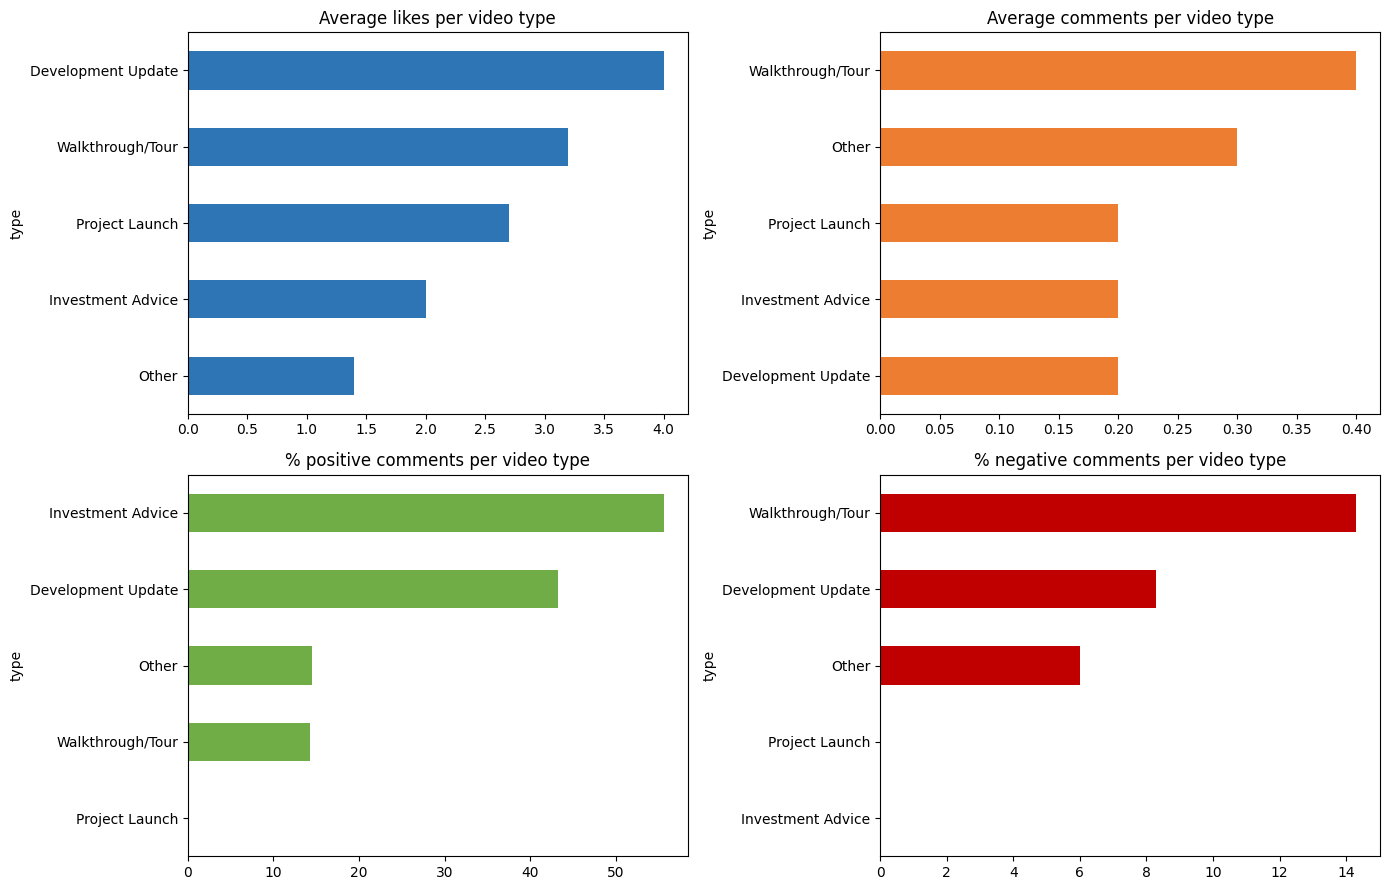

Most likes:       Development Update
Most comments:    Walkthrough/Tour
Most positive:    Investment Advice
Most negative:    Walkthrough/Tour


In [11]:
import pandas as pd
import matplotlib.pyplot as plt

videos = pd.read_csv("property_videos.csv")
comments = pd.read_csv("property_comments_sentiment.csv")

# 1. Classify each video by title keywords (first match wins)
rules = {
    "Payment Plan":       ["payment plan", "installment", "instalment", "easy plan", "down payment", "booking", "qist"],
    "Project Launch":     ["launch", "launching", "new project", "inauguration", "ground breaking", "announce", "introducing"],
    "Development Update": ["development", "update", "progress", "construction", "possession", "ballot", "status", "work in progress"],
    "Walkthrough/Tour":   ["tour", "walkthrough", "walk through", "visit", "site", "inside", "show home", "model apartment", "drone"],
    "Investment Advice":  ["invest", "investment", "profit", "return", "roi", "market", "price", "rates", "tips", "guide", "how to"],
}

def video_type(title):
    t = str(title).lower()
    for label, words in rules.items():
        if any(w in t for w in words):
            return label
    return "Other"

videos["type"] = videos["title"].apply(video_type)
print(videos["type"].value_counts(), "\n")

# 2. Merge sentiment with video types
merged = comments.merge(videos[["video_id", "type"]], on="video_id", how="left")

# 3. Summary table per video type
engagement = videos.groupby("type").agg(
    videos=("video_id", "count"),
    avg_views=("views", "mean"),
    avg_likes=("likes", "mean"),
    avg_comments=("comment_count", "mean"),
)
sent = merged.pivot_table(index="type", columns="sentiment", values="comment",
                          aggfunc="count", fill_value=0)
for col in ["positive", "neutral", "negative"]:
    if col not in sent.columns:
        sent[col] = 0
sent["total"] = sent[["positive", "neutral", "negative"]].sum(axis=1)
sent["pct_positive"] = (sent["positive"] / sent["total"] * 100).round(1)
sent["pct_negative"] = (sent["negative"] / sent["total"] * 100).round(1)

summary = engagement.join(sent[["total", "pct_positive", "pct_negative"]]).round(1)
summary.to_csv("summary_by_type.csv")
print(summary)

# 4. Four charts
fig, ax = plt.subplots(2, 2, figsize=(14, 9))

summary["avg_likes"].sort_values().plot.barh(ax=ax[0, 0], color="#2E75B6")
ax[0, 0].set_title("Average likes per video type")

summary["avg_comments"].sort_values().plot.barh(ax=ax[0, 1], color="#ED7D31")
ax[0, 1].set_title("Average comments per video type")

summary["pct_positive"].sort_values().plot.barh(ax=ax[1, 0], color="#70AD47")
ax[1, 0].set_title("% positive comments per video type")

summary["pct_negative"].sort_values().plot.barh(ax=ax[1, 1], color="#C00000")
ax[1, 1].set_title("% negative comments per video type")

plt.tight_layout()
plt.savefig("property_charts.png", dpi=200)
plt.show()

# 5. Quick answers
print("Most likes:      ", summary["avg_likes"].idxmax())
print("Most comments:   ", summary["avg_comments"].idxmax())
print("Most positive:   ", summary["pct_positive"].idxmax())
print("Most negative:   ", summary["pct_negative"].idxmax())

In [13]:
import pandas as pd

summary = pd.read_csv("summary_by_type.csv", index_col=0)

def recommend(summary, min_videos=5, min_comments=30):
    # Only trust groups with enough data
    s = summary[(summary["videos"] >= min_videos) & (summary["total"] >= min_comments)].copy()
    s = s.drop(index="Other", errors="ignore")
    if s.empty:
        return ["Not enough data per video type. Collect more videos or comments."]

    # Score = engagement (likes + comments, scaled 0-1) combined with sentiment
    def scale(col):
        return (col - col.min()) / (col.max() - col.min() + 1e-9)

    s["engagement"] = (scale(s["avg_likes"]) + scale(s["avg_comments"])) / 2
    s["sentiment_score"] = (s["pct_positive"] - s["pct_negative"]) / 100
    s["score"] = 0.5 * s["engagement"] + 0.5 * scale(s["sentiment_score"])
    s = s.sort_values("score", ascending=False)

    advice = []
    best, worst = s.index[0], s.index[-1]

    advice.append(
        f"POST MORE '{best}' content: highest overall score, "
        f"{s.loc[best, 'avg_likes']:.0f} avg likes, {s.loc[best, 'avg_comments']:.0f} avg comments, "
        f"{s.loc[best, 'pct_positive']:.0f}% positive comments."
    )
    if len(s) > 2:
        second = s.index[1]
        advice.append(
            f"KEEP '{second}' as a strong second option "
            f"({s.loc[second, 'pct_positive']:.0f}% positive)."
        )
    advice.append(
        f"REDUCE OR REWORK '{worst}' content: lowest score, "
        f"{s.loc[worst, 'pct_negative']:.0f}% negative comments, "
        f"{s.loc[worst, 'avg_likes']:.0f} avg likes."
    )

    # Extra flags
    angriest = s["pct_negative"].idxmax()
    if s.loc[angriest, "pct_negative"] > 20:
        advice.append(
            f"WATCH '{angriest}': {s.loc[angriest, 'pct_negative']:.0f}% negative comments. "
            f"Check what viewers are complaining about (price, delays, trust)."
        )
    most_discussed = s["avg_comments"].idxmax()
    if most_discussed != best:
        advice.append(f"'{most_discussed}' sparks the most discussion. Use it to drive questions and leads.")

    return advice

print("MARKETING RECOMMENDATIONS")
print("-" * 40)
for i, line in enumerate(recommend(summary), 1):
    print(f"{i}. {line}")

MARKETING RECOMMENDATIONS
----------------------------------------
1. POST MORE 'Development Update' content: highest overall score, 4 avg likes, 0 avg comments, 43% positive comments.
2. REDUCE OR REWORK 'Development Update' content: lowest score, 8% negative comments, 4 avg likes.


In [14]:
comments = pd.read_csv("property_comments_sentiment.csv")
neg = comments[comments["sentiment"] == "negative"].sort_values("likes", ascending=False)
print(neg[["clean_comment", "likes"]].head(15).to_string())

                                                                                                                                               clean_comment  likes
788                                                                                                                                  Price q nhi btatay hain      2
874                                                                                                                                  Malir mai hai ap k pass      1
1187                                                                                                                                     Block no street no?      1
616                                                                                                                                           No development      1
38                                                                                                       Iski latest video nhi a rhi ha Kya Kam bnd ho gya ?      1
0               

In [1]:
import pandas as pd, numpy as np

def generate(n, seed=42):
    rng = np.random.default_rng(seed)
    platforms = ["Facebook", "Instagram", "Google", "TikTok", "YouTube", "Zameen.com"]
    # (CTR, avg CPC in Rs, lead rate per click, avg revenue per lead in Rs)
    profile = {
        "Facebook":   (0.012, 25, 0.020, 150000),
        "Instagram":  (0.010, 30, 0.018, 170000),
        "Google":     (0.035, 60, 0.040, 220000),
        "TikTok":     (0.008, 15, 0.008, 90000),
        "YouTube":    (0.006, 20, 0.010, 130000),
        "Zameen.com": (0.025, 45, 0.050, 200000),
    }
    df = pd.DataFrame({
        "date": pd.to_datetime("2025-01-01") + pd.to_timedelta(rng.integers(0, 365, n), unit="D"),
        "platform": rng.choice(platforms, n),
        "property_type": rng.choice(["Plot", "Apartment", "House", "Commercial"], n, p=[.35, .30, .25, .10]),
        "listing_type": rng.choice(["Sale", "Rent"], n, p=[.7, .3]),
        "city": rng.choice(["Lahore", "Karachi", "Islamabad", "Faisalabad", "Rawalpindi"], n),
        "age": rng.integers(22, 60, n),
        "gender": rng.choice(["M", "F"], n, p=[.65, .35]),
        "device": rng.choice(["Mobile", "Desktop"], n, p=[.8, .2]),
    })
    df["campaign"] = df["platform"] + "_" + df["property_type"] + "_" + df["date"].dt.strftime("%b")
    df["impressions"] = rng.integers(2000, 50000, n)
    ctr = df["platform"].map(lambda p: profile[p][0])
    cpc = df["platform"].map(lambda p: profile[p][1])
    lead = df["platform"].map(lambda p: profile[p][2])
    rev = df["platform"].map(lambda p: profile[p][3])
    df["clicks"] = rng.binomial(df["impressions"], ctr * rng.uniform(0.7, 1.3, n))
    df["spend"] = (df["clicks"] * cpc * rng.uniform(0.8, 1.2, n)).round(2)
    df["conversions"] = rng.binomial(df["clicks"], lead)
    df["revenue"] = (df["conversions"] * rev * rng.uniform(0.5, 1.5, n)).round(2)
    return df

df = generate(10_000)
df.to_csv("property_ads_10k.csv", index=False)
print("Saved:", len(df), "rows")

Saved: 10000 rows


      10,000 rows | Pandas 0.12s | MapReduce 0.05s | Spark 0.96s
     100,000 rows | Pandas 0.02s | MapReduce 0.15s | Spark 1.29s
   1,000,000 rows | Pandas 0.11s | MapReduce 0.69s | Spark 1.67s
  10,000,000 rows | Pandas 1.11s | MapReduce 6.92s | Spark 3.23s

           Pandas  Spark  MapReduce
rows                              
10000       0.12   0.96       0.05
100000      0.02   1.29       0.15
1000000     0.11   1.67       0.69
10000000    1.11   3.23       6.92


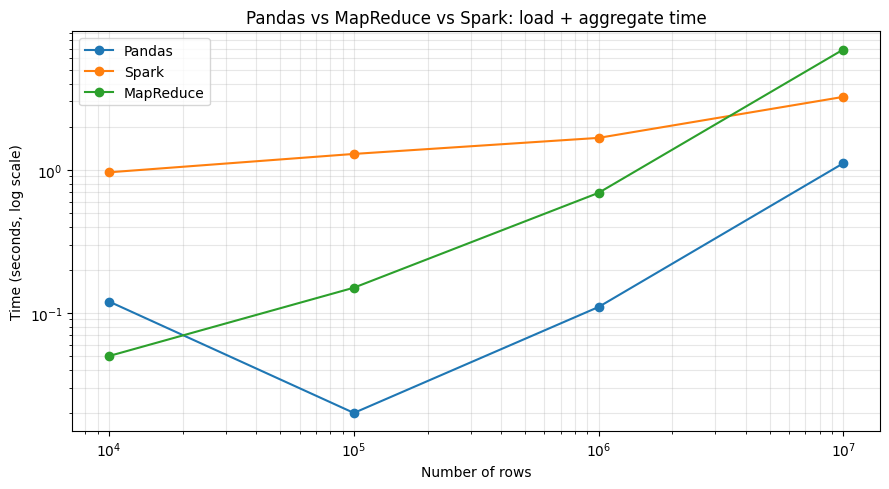

                   spend       revenue    ROAS      CPA
Facebook    1.300042e+10  1.560645e+12  120.05  1250.22
Instagram   1.300267e+10  1.326636e+12  102.03  1666.28
Google      9.108006e+10  1.335781e+13  146.66  1500.07
TikTok      5.200003e+09  2.497280e+11   48.02  1874.15
YouTube     5.197324e+09  3.379267e+11   65.02  1998.97
Zameen.com  4.870961e+10  1.082423e+13  222.22   899.90


In [2]:
!pip install pyspark -q
import os, time, multiprocessing as mp
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

SIZES = [10_000, 100_000, 1_000_000, 10_000_000]
RUN_MAPREDUCE_AT_10M = True   # set False if you are short on time (takes a few minutes)

PLATFORMS = ["Facebook", "Instagram", "Google", "TikTok", "YouTube", "Zameen.com"]
CTR  = np.array([0.012, 0.010, 0.035, 0.008, 0.006, 0.025])
CPC  = np.array([25, 30, 60, 15, 20, 45])
LEAD = np.array([0.020, 0.018, 0.040, 0.008, 0.010, 0.050])
REV  = np.array([150000, 170000, 220000, 90000, 130000, 200000])
COLS = ["impressions", "clicks", "spend", "conversions", "revenue"]

# ---------- 1. Generate data (compact types so 10M rows fits in memory) ----------
def gen(n, seed=42):
    rng = np.random.default_rng(seed)
    pid = rng.integers(0, 6, n).astype(np.int8)
    imp = rng.integers(2000, 50000, n).astype(np.int32)
    clk = rng.binomial(imp, CTR[pid] * rng.uniform(0.7, 1.3, n)).astype(np.int32)
    spend = clk * CPC[pid] * rng.uniform(0.8, 1.2, n)
    conv = rng.binomial(clk, LEAD[pid]).astype(np.int32)
    rev = conv * REV[pid] * rng.uniform(0.5, 1.5, n)
    return pd.DataFrame({"platform_id": pid, "impressions": imp, "clicks": clk,
                         "spend": spend, "conversions": conv, "revenue": rev})

# ---------- 2. Engine A: Pandas ----------
def run_pandas(path):
    df = pd.read_parquet(path)
    return df.groupby("platform_id")[COLS].sum()

# ---------- 3. Engine B: MapReduce (map -> combine -> shuffle -> reduce) ----------
def mr_map(bounds):
    """MAP: read each row, emit (platform, values). Local COMBINER sums per platform."""
    s, e = bounds
    local = {}
    for p, i, c, sp, cv, r in zip(P[s:e].tolist(), I[s:e].tolist(), C[s:e].tolist(),
                                  SP[s:e].tolist(), CV[s:e].tolist(), R[s:e].tolist()):
        acc = local.get(p)
        if acc is None:
            local[p] = [i, c, sp, cv, r]
        else:
            acc[0] += i; acc[1] += c; acc[2] += sp; acc[3] += cv; acc[4] += r
    return local

def run_mapreduce(path):
    global P, I, C, SP, CV, R
    df = pd.read_parquet(path)
    P, I, C = df.platform_id.values, df.impressions.values, df.clicks.values
    SP, CV, R = df.spend.values, df.conversions.values, df.revenue.values
    n = len(df)
    edges = np.linspace(0, n, 9, dtype=int)                    # 8 input splits
    splits = list(zip(edges[:-1], edges[1:]))
    with mp.Pool(os.cpu_count()) as pool:
        partials = pool.map(mr_map, splits)                    # MAP phase (parallel)
    final = {}                                                 # SHUFFLE + REDUCE phase
    for part in partials:
        for key, vals in part.items():
            if key not in final:
                final[key] = list(vals)
            else:
                final[key] = [a + b for a, b in zip(final[key], vals)]
    return pd.DataFrame.from_dict(final, orient="index", columns=COLS).sort_index()

# ---------- 4. Engine C: Spark ----------
spark = (SparkSession.builder.master("local[*]")
         .config("spark.driver.memory", "4g")
         .config("spark.sql.shuffle.partitions", "8")
         .config("spark.ui.showConsoleProgress", "false")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")

def run_spark(path):
    sdf = spark.read.parquet(path)
    out = (sdf.groupBy("platform_id")
              .agg(*[F.sum(c).alias(c) for c in COLS]).orderBy("platform_id").collect())
    return pd.DataFrame([r.asDict() for r in out]).set_index("platform_id")

# Warm-up so Spark's one-time startup cost doesn't distort the 10K result
gen(1000).to_parquet("warmup.parquet"); run_spark("warmup.parquet")

# ---------- 5. Run the experiment ----------
def timed(fn, path):
    t = time.perf_counter(); res = fn(path); return time.perf_counter() - t, res

results = []
for n in SIZES:
    path = f"ads_{n}.parquet"
    gen(n).to_parquet(path)
    row = {"rows": n}
    t_pd, r_pd = timed(run_pandas, path);  row["Pandas"] = t_pd
    t_sp, r_sp = timed(run_spark, path);   row["Spark"] = t_sp
    if n == 10_000_000 and not RUN_MAPREDUCE_AT_10M:
        row["MapReduce"] = np.nan
    else:
        t_mr, r_mr = timed(run_mapreduce, path); row["MapReduce"] = t_mr
        assert np.isclose(r_pd.spend.sum(), r_mr.spend.sum()), "MapReduce mismatch!"
    assert np.isclose(r_pd.spend.sum(), r_sp.spend.sum()), "Spark mismatch!"   # correctness check
    results.append(row)
    print(f"{n:>12,} rows | Pandas {row['Pandas']:.2f}s | MapReduce {row['MapReduce']:.2f}s | Spark {row['Spark']:.2f}s")

res = pd.DataFrame(results).set_index("rows").round(2)
res.to_csv("scale_results.csv")
print("\n", res)

# ---------- 6. Chart ----------
ax = res.plot(marker="o", figsize=(9, 5), logx=True, logy=True)
ax.set_xlabel("Number of rows"); ax.set_ylabel("Time (seconds, log scale)")
ax.set_title("Pandas vs MapReduce vs Spark: load + aggregate time")
ax.grid(True, which="both", alpha=0.3)
plt.tight_layout(); plt.savefig("scale_chart.png", dpi=200); plt.show()

# ROAS from the largest run, to show all engines agree
final = r_pd.copy()
final["ROAS"] = final.revenue / final.spend
final["CPA"] = final.spend / final.conversions
final.index = [PLATFORMS[i] for i in final.index]
print(final[["spend", "revenue", "ROAS", "CPA"]].round(2))

BUDGET RECOMMENDATION FOR Rs. 1,000,000
---------------------------------------------
Zameen.com    39.3%   Rs.   393,000   (ROAS 221.9, CPA Rs. 899, now 27.6%)
Google        19.8%   Rs.   198,000   (ROAS 145.8, CPA Rs. 1,510, now 51.8%)
Facebook      14.4%   Rs.   144,000   (ROAS 116.1, CPA Rs. 1,273, now 7.4%)
Instagram     12.0%   Rs.   120,000   (ROAS 99.9, CPA Rs. 1,668, now 7.3%)
YouTube        7.9%   Rs.    79,000   (ROAS 65.0, CPA Rs. 1,986, now 2.9%)
TikTok         6.6%   Rs.    66,000   (ROAS 48.5, CPA Rs. 1,852, now 3.0%)
---------------------------------------------
Expected revenue, current mix:     Rs. 156,085,898
Expected revenue, recommended mix: Rs. 153,124,094  (-1.9%)

BEST TARGETING PER PLATFORM (by ROAS, min 100 rows)
  Facebook    best city          : Islamabad (ROAS 119.7)
  Facebook    best property_type : Commercial (ROAS 119.4)
  Facebook    best device        : Mobile (ROAS 117.6)
  Google      best city          : Faisalabad (ROAS 149.1)
  Google      best p

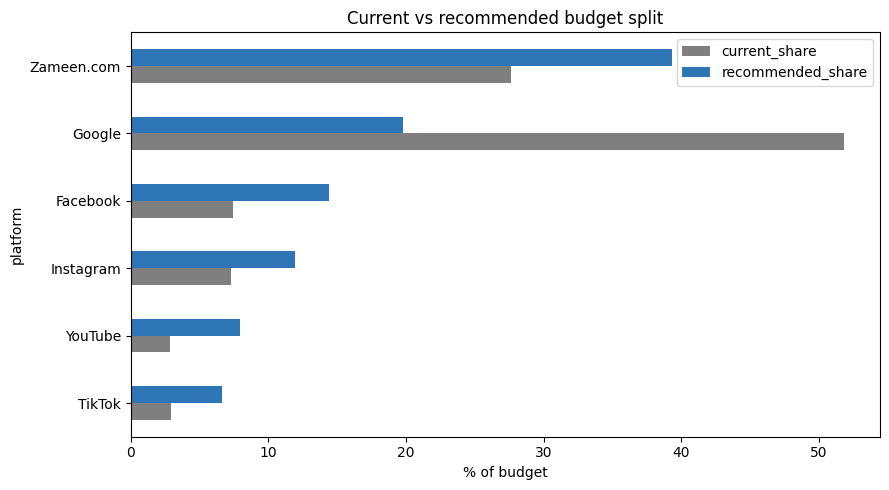

In [3]:
import os, pandas as pd, numpy as np
import matplotlib.pyplot as plt

# ---- Load data (rebuild if the session was reset) ----
if not os.path.exists("property_ads_10k.csv"):
    raise SystemExit("File missing: rerun the data generator cell from Step 1 first.")
df = pd.read_csv("property_ads_10k.csv")

BUDGET = 1_000_000          # Rs. 1 million
MIN_SHARE, MAX_SHARE = 0.05, 0.40   # no platform below 5% or above 40%
POWER = 2                   # higher = rewards top performers more

# ---- 1. Platform performance ----
p = df.groupby("platform").agg(spend=("spend", "sum"), revenue=("revenue", "sum"),
                               conversions=("conversions", "sum"))
p["ROAS"] = p.revenue / p.spend
p["CPA"] = p.spend / p.conversions
p["current_share"] = p.spend / p.spend.sum()

# ---- 2. Allocation with floor and cap ----
def allocate(score, lo, hi):
    n = len(score)
    extra_total = 1 - lo * n                 # share left after giving everyone the floor
    cap = hi - lo
    alloc = pd.Series(0.0, index=score.index)
    free, remaining = list(score.index), extra_total
    while free:
        prop = score[free] / score[free].sum() * remaining
        over = prop[prop > cap].index
        if len(over) == 0:
            alloc[free] = prop
            break
        alloc[over] = cap                     # fix capped platforms
        remaining -= cap * len(over)
        free = [f for f in free if f not in over]
    return alloc + lo

p["recommended_share"] = allocate(p.ROAS ** POWER, MIN_SHARE, MAX_SHARE)
p["budget_rs"] = (p.recommended_share * BUDGET).round(-3)
p["expected_revenue"] = p.budget_rs * p.ROAS
p["expected_leads"] = (p.budget_rs / p.CPA).round(0)

# ---- 3. Compare with the current mix ----
cur_rev = (p.current_share * BUDGET * p.ROAS).sum()
new_rev = p.expected_revenue.sum()

print(f"BUDGET RECOMMENDATION FOR Rs. {BUDGET:,}")
print("-" * 45)
for plat, r in p.sort_values("recommended_share", ascending=False).iterrows():
    print(f"{plat:<12} {r.recommended_share*100:5.1f}%   Rs. {r.budget_rs:>9,.0f}   "
          f"(ROAS {r.ROAS:.1f}, CPA Rs. {r.CPA:,.0f}, now {r.current_share*100:.1f}%)")
print("-" * 45)
print(f"Expected revenue, current mix:     Rs. {cur_rev:,.0f}")
print(f"Expected revenue, recommended mix: Rs. {new_rev:,.0f}  ({(new_rev/cur_rev-1)*100:+.1f}%)")

# ---- 4. Best segment for each platform ----
print("\nBEST TARGETING PER PLATFORM (by ROAS, min 100 rows)")
for plat in p.index:
    d = df[df.platform == plat]
    for col in ["city", "property_type", "device"]:
        g = d.groupby(col).filter(lambda x: len(x) >= 100).groupby(col)[["revenue", "spend"]].sum()
        g = (g.revenue / g.spend).sort_values(ascending=False)
        print(f"  {plat:<11} best {col:<14}: {g.index[0]} (ROAS {g.iloc[0]:.1f})")

# ---- 5. Chart ----
ax = p[["current_share", "recommended_share"]].mul(100).sort_values("recommended_share").plot.barh(
    figsize=(9, 5), color=["#7F7F7F", "#2E75B6"])
ax.set_xlabel("% of budget"); ax.set_title("Current vs recommended budget split")
plt.tight_layout(); plt.savefig("budget_recommendation.png", dpi=200); plt.show()
p.round(3).to_csv("budget_recommendation.csv")